# Validating the `spey-roofit` plug-in

This notebook validates [`spey-roofit`](https://github.com/SpeysideHEP/spey-roofit),
the [`RooFit`](https://root.cern/manual/roofit/) backend for
[`spey`](https://spey.readthedocs.io), on four independent fronts:

1. **Against `spey`'s own likelihoods.** Two `HistFactory` workspaces are built that are
   mathematically identical to `default.uncorrelated_background` and
   `default.correlated_background`, and every quantity `spey` can compute is compared
   between the two implementations.
2. **Against `pyhf`,** through the [`spey-pyhf`](https://github.com/SpeysideHEP/spey-pyhf)
   plug-in, so that both sides are driven by the same `spey` interface and only the
   likelihood implementation differs. `pyhf` uses the same Asimov conventions as
   `RooFit`, so the agreement is expected to be exact for the likelihood, the Asimov
   data *and* the exclusion limits.
3. **The behaviour of the test statistic and of the limits.** The distribution of
   $t_\mu$ over 2000 toys is compared against $\chi^2_1$ and between the three
   implementations, and the expected exclusion is drawn as a Brazilian plot.
4. **Against the published ATLAS monojet analysis**
   ([arXiv:2102.10874](https://arxiv.org/abs/2102.10874),
   [HEPData ins1847779](https://www.hepdata.net/record/ins1847779)). The interpreter has
   to reproduce the published yields of all 78 regions, and the profile likelihood has to
   recover the signal strength stored in the published post-fit workspace.

Run it in the environment described by `environment.yml`.

> **Runtime.** Sections 1 to 3 run in seconds. Section 4 throws 2000 toys through
> three backends and takes a few minutes. The two exclusion limits at the very end are
> full profile-likelihood scans of a 150-parameter model and take a few minutes each;
> all outputs are stored in this notebook, so it can be read without re-running it.


In [ ]:
import json
import os
import sys
import time

import numpy as np
import spey
from spey.system.logger import disable_logging

import spey_roofit
from spey_roofit import WorkspaceInterpreter, load_workspace
from spey_roofit.data import WorkspaceData


def find_repository(start=None):
    """Walk up from `start` until the directory holding pyproject.toml is found."""
    directory = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.exists(os.path.join(directory, "pyproject.toml")):
            return directory
        parent = os.path.dirname(directory)
        if parent == directory:
            raise RuntimeError("run this notebook from inside the repository")
        directory = parent


REPOSITORY = find_repository()
sys.path.insert(0, os.path.join(REPOSITORY, "tests"))
ATLAS = os.path.join(REPOSITORY, "atlas-exot-2018-06")
WORKDIR = os.path.join(ATLAS, "_generated")
os.makedirs(WORKDIR, exist_ok=True)

print("spey        ", spey.__version__)
print("spey-roofit ", spey_roofit.__version__)
print("ROOT        ", spey_roofit.manager.version)
print("backends    ", [b for b in spey.AvailableBackends() if "roofit" in b])

Spey - WARNING: An unstable version of Spey (0.2.8-b1) is being used. Latest stable version is 0.2.7.


spey         0.2.8-b1
spey-roofit  0.0.1


ROOT         6.36.04
backends     ['root.roofit']


---
## 1. A `RooFit` twin of `spey`'s uncorrelated-background likelihood

`spey`'s `default.uncorrelated_background` backend implements

$$
\mathcal{L}(\mu,\theta)=\prod_i \mathrm{Pois}\!\left(n_i\,\middle|\,\mu s_i+b_i+\theta_i\sigma_i\right)
\cdot\prod_i \mathrm{Gauss}\!\left(0\,\middle|\,\theta_i,1\right).
$$

The same model is expressed in `HistFactory` by giving each bin its own `HistoSys` whose
up and down templates are $b_i\pm\sigma_i$: the piecewise-linear interpolation is then
exact and the constraint is the usual unit Gaussian on $\alpha$. The helper that builds
it lives in `tests/toy_models.py`.

In [2]:
from toy_models import correlated_background_workspace, uncorrelated_background_workspace

background = [50.0, 60.0, 30.0]
signal = [12.0, 11.0, 5.0]
uncertainty = [3.0, 5.0, 2.0]
observed = [51.0, 48.0, 32.0]

uncorrelated_path = uncorrelated_background_workspace(
    WORKDIR, background, signal, observed, uncertainty
)

### What the interpreter sees

The interpreter is the user-facing view of a workspace: it lists the regions, their
binning, the samples and their yields, without requiring any knowledge of `RooFit`.

In [3]:
interpreter = WorkspaceInterpreter(uncorrelated_path)
print(interpreter.summary())

RooFit workspace 'combined'
  channels            : 1
  bins                : 3
  parameters of interest : mu
  nuisance parameters : 3
  global observables  : 3

  [__unknown__] ch (3 bins)
      observed   : [51, 48, 32]
      background : [50, 60, 30]
      signal     : [12, 11, 5]
        - bkg: [50, 60, 30]
        - sig (signal): [12, 11, 5]
RooFit workspace 'combined'
  channels            : 1
  bins                : 3
  parameters of interest : mu
  nuisance parameters : 3
  global observables  : 3

  [__unknown__] ch (3 bins)
      observed   : [51, 48, 32]
      background : [50, 60, 30]
      signal     : [12, 11, 5]
        - bkg: [50, 60, 30]
        - sig (signal): [12, 11, 5]


In [4]:
roofit = spey.get_backend("root.roofit")(
    workspace=uncorrelated_path, analysis="roofit-toy"
)
reference = spey.get_backend("default.uncorrelated_background")(
    signal_yields=signal,
    background_yields=background,
    data=observed,
    absolute_uncertainties=uncertainty,
    analysis="spey-toy",
)

config = roofit.backend.config()
print("parameters :", config.parameter_names)
print("poi index  :", config.poi_index)
print(
    "minimum poi:", config.minimum_poi, "vs spey", reference.backend.config().minimum_poi
)

parameters : ['mu', 'alpha_theta0', 'alpha_theta1', 'alpha_theta2']
poi index  : 0
minimum poi: -4.166666666666667 vs spey -4.166666666666667


### Log-likelihood

The first and most important check: the two backends must return the *same number* for
$\log\mathcal{L}(\mu,\theta)$, not just the same likelihood ratios. `RooFit` normalises its
negative log-likelihood differently from `spey` — it adds data-dependent but
parameter-independent terms such as the category normalisation of a `RooSimultaneous` —
and the plug-in calibrates that offset away once per dataset.

In [5]:
ours = roofit.backend.get_logpdf_func()
theirs = reference.backend.get_logpdf_func()

rng = np.random.default_rng(2024)
rows = []
for _ in range(8):
    pars = np.concatenate([[rng.uniform(-2.0, 3.0)], rng.normal(0.0, 0.8, 3)])
    rows.append((pars, ours(pars), theirs(pars)))

print(f"{'mu':>8s} {'roofit logL':>18s} {'spey logL':>18s} {'difference':>14s}")
for pars, a, b in rows:
    print(f"{pars[0]:8.3f} {a:18.12f} {b:18.12f} {a - b:14.2e}")
print()
print("max |difference| =", max(abs(a - b) for _, a, b in rows))

      mu        roofit logL          spey logL     difference
   1.379   -23.271320091408   -23.271320091407      -2.84e-14
   2.979   -36.926006579485   -36.926006579485       4.26e-14
  -0.202   -13.319795056460   -13.319795056460      -2.84e-14
  -1.473   -16.287664473832   -16.287664473832       0.00e+00
   2.878   -31.104925608414   -31.104925608414       1.42e-14
  -0.968   -16.028035687426   -16.028035687426      -2.84e-14
   2.036   -24.335757729709   -24.335757729709       3.20e-14
   0.336   -13.537772303338   -13.537772303338       0.00e+00

max |difference| = 4.263256414560601e-14


### Everything `spey` derives from the likelihood

`likelihood`, `maximize_likelihood` and the observed exclusion are compared directly.

In [6]:
def compare(name, fn, tolerance=1e-6):
    a, b = fn(roofit), fn(reference)
    a, b = float(np.ravel(a)[0]), float(np.ravel(b)[0])
    delta = abs(a - b) / max(abs(b), 1e-12)
    flag = "ok" if delta < tolerance else "differs"
    print(f"{name:34s} {a:16.10f} {b:16.10f} {delta:10.2e}  {flag}")


print(f"{'quantity':34s} {'spey-roofit':>16s} {'spey default':>16s} {'rel. diff':>10s}")
compare("likelihood(mu=0)", lambda m: m.likelihood(0.0))
compare("likelihood(mu=1)", lambda m: m.likelihood(1.0))
compare("likelihood(mu=2)", lambda m: m.likelihood(2.0))
compare("maximize_likelihood -> muhat", lambda m: m.maximize_likelihood()[0], 1e-3)
compare("maximize_likelihood -> nll", lambda m: m.maximize_likelihood()[1])
compare("asimov_likelihood(mu=1)", lambda m: m.asimov_likelihood(1.0), 1e-1)
compare("maximize_asimov_likelihood", lambda m: m.maximize_asimov_likelihood()[1], 1e-1)
compare("exclusion_confidence_level", lambda m: m.exclusion_confidence_level()[0], 1e-2)
compare("poi_upper_limit", lambda m: m.poi_upper_limit(), 1e-1)

quantity                                spey-roofit     spey default  rel. diff
likelihood(mu=0)                      12.1379528821    12.1379528175   5.32e-09  ok
likelihood(mu=1)                      15.3485728768    15.3485728968   1.31e-09  ok
likelihood(mu=2)                      22.0472740180    22.0472740222   1.90e-10  ok
maximize_likelihood -> muhat          -0.2386707789    -0.2387243068   2.24e-04  ok
maximize_likelihood -> nll            12.0017105894    12.0017103063   2.36e-08  ok
asimov_likelihood(mu=1)               13.3238188616    13.3238246489   4.34e-07  ok
maximize_asimov_likelihood            11.1969570301    11.1969591683   1.91e-07  ok
exclusion_confidence_level             0.9838873970     0.9838874178   2.11e-08  ok


poi_upper_limit                        0.7904797341     0.7904795164   2.75e-07  ok


In [7]:
print("Asimov data")
print("  spey-roofit :", np.round(roofit.generate_asimov_data(), 6))
print("  spey default:", np.round(reference.generate_asimov_data(), 6))

Asimov data
  spey-roofit : [ 5.0151384e+01  5.6310481e+01  3.0232837e+01  5.0461000e-02
 -7.3790400e-01  1.1641900e-01]
  spey default: [ 5.0151258e+01  5.6309521e+01  3.0233577e+01  5.0419000e-02
 -7.3809600e-01  1.1678800e-01]


---
## 2. A `RooFit` twin of the correlated-background likelihood

`default.correlated_background` constrains the background with a correlated Gaussian,
$\theta\sim\mathcal{N}(0,\rho)$ and $\lambda_i=\mu s_i+b_i+\sigma_i\theta_i$.
Factorising $\Sigma=LL^{T}$ and using the columns of $L$ as `HistoSys` templates gives the
*same* model written in an uncorrelated basis, $\lambda_i=\mu s_i+b_i+\sum_k L_{ik}z_k$
with $z\sim\mathcal{N}(0,\mathbb{1})$.

Changing basis multiplies the likelihood by a constant Jacobian, so the two
log-likelihoods differ by exactly $\tfrac12\log\det\rho$ — and every likelihood ratio,
and therefore every inference result, is unchanged.

In [8]:
covariance = np.array([[9.0, 2.0, 1.0], [2.0, 25.0, 3.0], [1.0, 3.0, 4.0]])
correlated_path = correlated_background_workspace(
    WORKDIR, background, signal, observed, covariance
)

factor = np.linalg.cholesky(covariance)
scale = np.diag(np.sqrt(np.diag(covariance)))
correlation = np.linalg.inv(scale) @ covariance @ np.linalg.inv(scale)
constant = 0.5 * np.log(np.linalg.det(correlation))

roofit_corr = spey.get_backend("root.roofit")(
    workspace=correlated_path, analysis="roofit-corr"
)
reference_corr = spey.get_backend("default.correlated_background")(
    signal_yields=signal,
    background_yields=background,
    data=observed,
    covariance_matrix=covariance,
    analysis="spey-corr",
)

ours = roofit_corr.backend.get_logpdf_func()
theirs = reference_corr.backend.get_logpdf_func()

print("predicted constant offset = 0.5 log|rho| =", constant)
print()
rng = np.random.default_rng(7)
for _ in range(5):
    poi = rng.uniform(-1.0, 2.0)
    latent = rng.normal(0.0, 1.0, 3)
    theta = np.linalg.inv(scale) @ (factor @ latent)
    delta = ours(np.concatenate([[poi], latent])) - theirs(np.concatenate([[poi], theta]))
    print(
        f"  mu={poi:7.4f}   logL difference = {delta:.12f}   residual = {delta - constant:.2e}"
    )

predicted constant offset = 0.5 log|rho| = -0.06518090893162179

  mu= 0.8753   logL difference = -0.065180908932   residual = -1.30e-15
  mu=-0.0995   logL difference = -0.065180908932   residual = 4.72e-16
  mu= 1.3912   logL difference = -0.065180908932   residual = -2.97e-14
  mu=-0.2354   logL difference = -0.065180908932   residual = 4.72e-16
  mu= 1.9865   logL difference = -0.065180908932   residual = -1.20e-14


In [9]:
print("muhat  spey-roofit:", roofit_corr.maximize_likelihood()[0])
print("muhat  spey default:", reference_corr.maximize_likelihood()[0])

muhat  spey-roofit: -0.2338623753584183
muhat  spey default: -0.23383961360044084


---
## 3. Cross-check against `pyhf`, through `spey-pyhf`

`pyhf` implements the same `HistFactory` statistical model, including the convention that
the auxiliary data of an Asimov dataset follow the nuisance parameters. The agreement with
`spey-roofit` should therefore be exact for the likelihood, the Asimov data and
$\mathrm{CL}_s$.

The comparison goes through the [`spey-pyhf`](https://github.com/SpeysideHEP/spey-pyhf)
plug-in rather than through `pyhf` directly: both models are then `spey`
`StatisticalModel`s, asked the same questions by the same interface, and the only thing
that differs between them is how the likelihood is evaluated.

In [ ]:
import spey_pyhf

from toy_models import uncorrelated_background_pyhf_workspace

# spey-pyhf picks the jax tensor backend whenever jax is importable. numpy is
# pyhf's own reference implementation and has no platform-dependent precision,
# which is what a number-by-number comparison wants.
spey_pyhf.manager.backend = "numpy"
print("pyhf tensor backend:", spey_pyhf.manager.backend, "\n")

# spey-pyhf takes a background-only workspace plus a JSON patch that adds the
# signal - the same split a reinterpretation would use.
pyhf_workspace, pyhf_patch = uncorrelated_background_pyhf_workspace(
    background, signal, observed, uncertainty
)
pyhf_model = spey.get_backend("pyhf")(
    background_only_model=pyhf_workspace,
    signal_patch=pyhf_patch,
    analysis="spey-pyhf",
)
print("is_alive:", pyhf_model.backend.is_alive)

our_names = roofit.backend.model.parameter_names
their_names = list(pyhf_model.backend.config().parameter_names)
their_init = np.asarray(pyhf_model.backend.config().suggested_init, dtype=float)
# HistFactory calls a constrained nuisance parameter alpha_theta0, pyhf theta0.
renamed = [n[len("alpha_") :] if n.startswith("alpha_") else n for n in our_names]
positions = [their_names.index(name) for name in renamed]
print("spey-roofit parameters:", our_names)
print("spey-pyhf   parameters:", their_names)


def to_pyhf(pars):
    """Rearrange a spey-roofit parameter vector into spey-pyhf's ordering."""
    translated = their_init.copy()
    for source, target in enumerate(positions):
        translated[target] = pars[source]
    return translated


ours = roofit.backend.get_logpdf_func()
theirs = pyhf_model.backend.get_logpdf_func()
print(f"\n{'mu':>8s} {'spey-roofit':>18s} {'spey-pyhf':>18s} {'difference':>12s}")
rng = np.random.default_rng(5)
for _ in range(6):
    pars = np.concatenate([[rng.uniform(-1.0, 2.0)], rng.normal(0.0, 0.6, 3)])
    a, b = ours(pars), theirs(to_pyhf(pars))
    print(f"{pars[0]:8.3f} {a:18.12f} {b:18.12f} {a - b:12.2e}")

pyhf tensor backend: numpy 

is_alive: True
spey-roofit parameters: ['mu', 'alpha_theta0', 'alpha_theta1', 'alpha_theta2']
spey-pyhf   parameters: ['theta0', 'theta1', 'theta2', 'mu']

      mu        spey-roofit          spey-pyhf   difference
   1.415   -19.005944789536   -19.005944789536     0.00e+00
  -0.838   -13.624390443469   -13.624390443469     1.78e-15
  -0.854   -13.922211470312   -13.922211470312    -2.84e-14
   0.305   -14.732287528948   -14.732287528948     0.00e+00
   0.177   -12.869209703360   -12.869209703360     2.84e-14
   0.667   -14.880534353204   -14.880534353204     0.00e+00


In [ ]:
pars = [1.0, 0.3, -0.4, 0.2]
print("expected data (Asimov), bin counts followed by auxiliary measurements")
print("  spey-roofit:", np.round(roofit.backend.expected_data(pars), 10))
print(
    "  spey-pyhf  :", np.round(pyhf_model.backend.expected_data(list(to_pyhf(pars))), 10)
)
print()
print("CLs at mu = 1  (1 - CLs)")
print("  spey-roofit:", roofit.exclusion_confidence_level()[0])
print("  spey-pyhf  :", pyhf_model.exclusion_confidence_level()[0])

expected data (Asimov), bin counts followed by auxiliary measurements
  spey-roofit: [62.9 69.  35.4  0.3 -0.4  0.2]
  spey-pyhf  : [62.9 69.  35.4  0.3 -0.4  0.2]

CLs at mu = 1  (1 - CLs)
  spey-roofit: 0.9838873970377554
  spey-pyhf  : 0.9838872017030073


---
## 4. The distribution of the test statistic

A likelihood is more than a number: the *distribution* of the test statistic it produces
is what turns a fit into a $p$-value. Wilks' theorem says that, for data generated at
$\mu$, the profile-likelihood test statistic

$$
t_\mu = -2\log\frac{\mathcal{L}(\mu,\hat{\hat\theta}_\mu)}{\mathcal{L}(\hat\mu,\hat\theta)}
$$

follows a $\chi^2_1$ distribution asymptotically.

The pseudo-data are drawn **once**, from the `spey-roofit` sampler, and then evaluated
with all three implementations of this model — `RooFit`, `spey`'s own likelihood and
`pyhf` — so any difference between them is in the likelihood rather than in the random
numbers. Each pseudo-dataset consists of the bin counts *and* the auxiliary measurements,
both of which fluctuate, which makes this a sharper probe than the Asimov comparison of
section 1: there the auxiliary data are derived, here they are thrown.

In [ ]:
from spey.optimizer.core import fit


def test_statistic(backend, data, poi_test):
    """Profile-likelihood test statistic t_mu for one pseudo-dataset."""
    config = backend.config(allow_negative_signal=True)
    logpdf = backend.get_logpdf_func(data=data)

    def negative(pars):
        return -logpdf(pars)

    conditional, _ = fit(
        func=negative, model_configuration=config, fixed_poi_value=poi_test
    )
    unconditional, _ = fit(func=negative, model_configuration=config)
    return 2.0 * (conditional - unconditional)


POI_TEST = 1.0
N_TOYS = 2000

np.random.seed(20240923)
toys = roofit.backend.get_sampler(np.array([POI_TEST, 0.0, 0.0, 0.0]))(N_TOYS)

# spey-roofit and spey-pyhf lay the data vector out the same way here: three
# bins in channel order, then the three auxiliary measurements. Section 3
# checked that on the Asimov dataset.
start = time.time()
statistics = {
    "spey-roofit": np.array([test_statistic(roofit.backend, t, POI_TEST) for t in toys]),
    "spey": np.array([test_statistic(reference.backend, t, POI_TEST) for t in toys]),
    "spey-pyhf": np.array(
        [test_statistic(pyhf_model.backend, t, POI_TEST) for t in toys]
    ),
}
print(f"{N_TOYS} toys through three backends in {time.time() - start:.0f} s")

finite = np.all([np.isfinite(v) for v in statistics.values()], axis=0)
print(f"usable toys: {finite.sum()} / {N_TOYS}\n")

print(f"{'':<14} {'mean':>8} {'median':>8} {'90th pct':>9}")
print(f"{'chi2_1':<14} {1.0:>8.4f} {0.4549:>8.4f} {2.7055:>9.4f}")
for name, values in statistics.items():
    v = values[finite]
    print(
        f"{name:<14} {v.mean():>8.4f} {np.median(v):>8.4f} "
        f"{np.percentile(v, 90):>9.4f}"
    )

pairs = [("spey-roofit", "spey"), ("spey-roofit", "spey-pyhf")]
print()
for a, b in pairs:
    delta = np.max(np.abs(statistics[a][finite] - statistics[b][finite]))
    print(f"largest |t_mu({a}) - t_mu({b})|: {delta:.2e}")

2000 toys through three backends in 175 s
usable toys: 2000 / 2000

                   mean   median  90th pct
chi2_1           1.0000   0.4549    2.7055
spey-roofit      1.0188   0.5150    2.6306
spey             1.0188   0.5150    2.6306
spey-pyhf        1.0188   0.5150    2.6306

largest |t_mu(spey-roofit) - t_mu(spey)|: 1.53e-06
largest |t_mu(spey-roofit) - t_mu(spey-pyhf)|: 1.01e-06


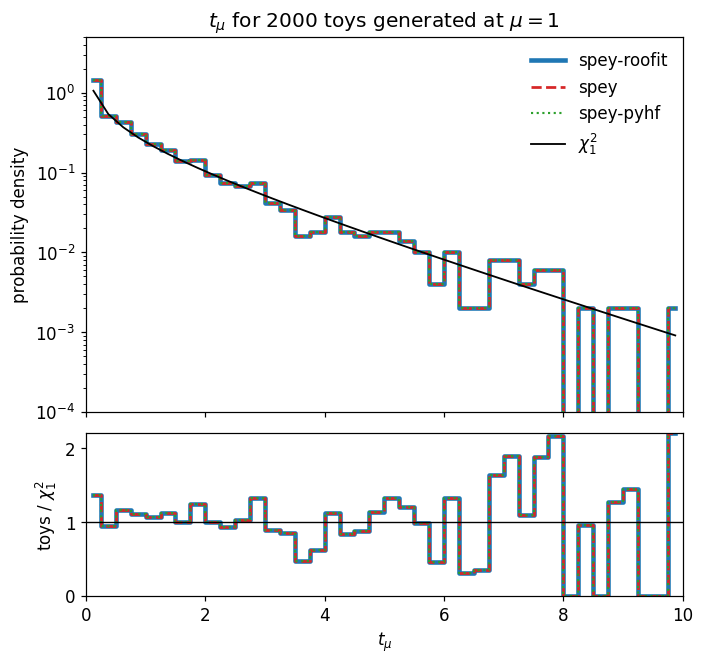

Kolmogorov-Smirnov against chi2_1:
  spey-roofit    D = 0.0320   p = 0.032
  spey           D = 0.0320   p = 0.032
  spey-pyhf      D = 0.0320   p = 0.032


In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

fig, (upper, lower) = plt.subplots(
    2,
    1,
    figsize=(7.0, 6.6),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.08},
)

edges = np.linspace(0.0, 10.0, 41)
centres = 0.5 * (edges[1:] + edges[:-1])
expected = stats.chi2.pdf(centres, df=1)

# The three curves coincide, so they are drawn thick to thin.
styles = [
    ("spey-roofit", "#1f77b4", "-", 3.0),
    ("spey", "#d62728", "--", 1.8),
    ("spey-pyhf", "#2ca02c", ":", 1.4),
]
densities = {}
for name, colour, dash, width in styles:
    density, _ = np.histogram(statistics[name][finite], bins=edges, density=True)
    densities[name] = density
    upper.step(centres, density, where="mid", lw=width, ls=dash, color=colour, label=name)
upper.plot(centres, expected, color="k", lw=1.2, label=r"$\chi^2_1$")
upper.set_yscale("log")
upper.set_ylim(1e-4, 5.0)
upper.set_ylabel("probability density")
upper.set_title(rf"$t_\mu$ for {finite.sum()} toys generated at $\mu={POI_TEST:g}$")
upper.legend(frameon=False)

with np.errstate(divide="ignore", invalid="ignore"):
    for name, colour, dash, width in styles:
        ratio = np.where(expected > 0, densities[name] / expected, np.nan)
        lower.step(centres, ratio, where="mid", lw=width, ls=dash, color=colour)
lower.axhline(1.0, color="k", lw=0.9)
lower.set_ylim(0.0, 2.2)
lower.set_ylabel(r"toys / $\chi^2_1$")
lower.set_xlabel(r"$t_\mu$")
lower.set_xlim(edges[0], edges[-1])

plt.show()

print("Kolmogorov-Smirnov against chi2_1:")
for name in statistics:
    result = stats.kstest(statistics[name][finite], "chi2", args=(1,))
    print(f"  {name:<14} D = {result.statistic:.4f}   p = {result.pvalue:.3f}")

The three curves coincide — `spey` and `spey-pyhf` are drawn thinner on top of
`spey-roofit` — because they are the same likelihood evaluated on the same pseudo-data.
Their test statistics agree to $1.5\times10^{-6}$ and $1.0\times10^{-6}$ respectively,
which is the tolerance of the minimiser, not a property of any of the models. The three
summary rows are identical to four decimals.

All three deviate from $\chi^2_1$ by the same, modest amount: the mean is 2% high, the
median sits at 0.515 against 0.455, and the Kolmogorov–Smirnov test gives $D=0.032$,
$p\approx0.03$ for each. That is not a defect of any implementation. Wilks' theorem is
asymptotic, and this model has three bins with about fifty events each, so a deviation of
this size is what one should expect — the boundary at $\hat\mu$ and the finite counts both
contribute. The point of the comparison is that whatever the deviation is, all three
backends reproduce it identically.

---
## 5. Expected exclusion: the Brazilian plot

The standard sensitivity summary: expected $\mathrm{CL}_s$ as a function of the signal
strength, with the $\pm1\sigma$ and $\pm2\sigma$ bands of the background-only expectation,
and the observed curve on top — computed once with each of the three backends.

In [ ]:
scan = np.linspace(0.05, 2.0, 24)
apriori = spey.ExpectationType.apriori
models = {"spey-roofit": roofit, "spey": reference, "spey-pyhf": pyhf_model}

start = time.time()
bands = {
    name: np.array(
        [model.exclusion_confidence_level(poi_test=mu, expected=apriori) for mu in scan]
    )
    for name, model in models.items()
}
observed_cls = {
    name: np.array([model.exclusion_confidence_level(poi_test=mu)[0] for mu in scan])
    for name, model in models.items()
}
print(f"scanned {len(scan)} points with three backends in {time.time() - start:.0f} s\n")

for name, model in models.items():
    print(
        f"{name:<14} expected 95% CL upper limit on mu: "
        f"{model.poi_upper_limit(expected=apriori):.6f}"
    )

print()
for name in ("spey", "spey-pyhf"):
    print(
        f"largest |expected CLs difference| vs spey-roofit, {name:<10}: "
        f"{np.max(np.abs(bands['spey-roofit'][:, 2] - bands[name][:, 2])):.2e}"
    )
    print(
        f"largest |observed CLs difference| vs spey-roofit, {name:<10}: "
        f"{np.max(np.abs(observed_cls['spey-roofit'] - observed_cls[name])):.2e}"
    )

scanned 24 points with three backends in 6 s



spey-roofit    expected 95% CL upper limit on mu: 0.953949


spey           expected 95% CL upper limit on mu: 0.953944


spey-pyhf      expected 95% CL upper limit on mu: 0.953948

largest |expected CLs difference| vs spey-roofit, spey      : 2.50e-06
largest |observed CLs difference| vs spey-roofit, spey      : 2.18e-06
largest |expected CLs difference| vs spey-roofit, spey-pyhf : 4.91e-07
largest |observed CLs difference| vs spey-roofit, spey-pyhf : 1.79e-06


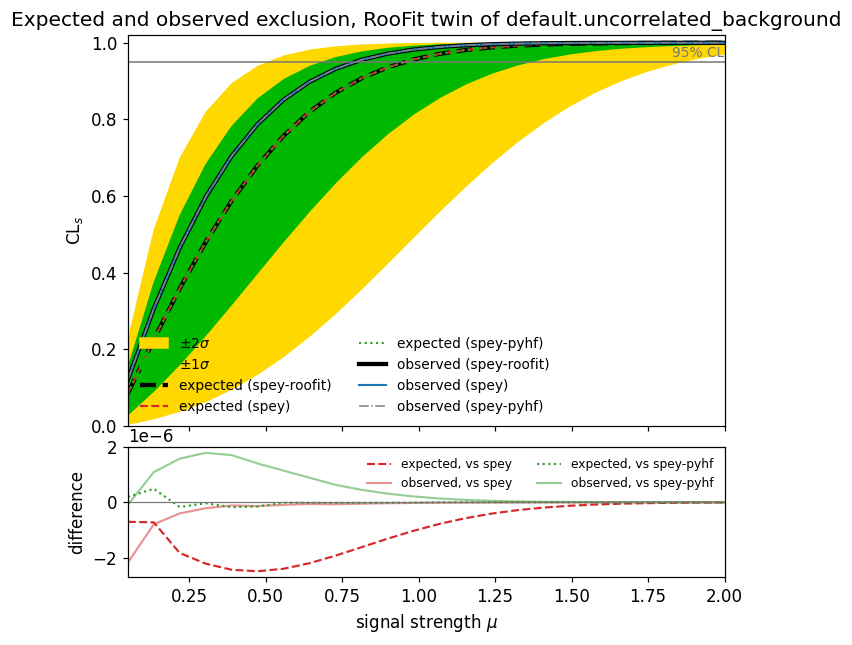

In [ ]:
fig, (upper, lower) = plt.subplots(
    2,
    1,
    figsize=(7.0, 6.4),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08},
)

# spey returns the bands ordered -2sigma, -1sigma, median, +1sigma, +2sigma.
ours = bands["spey-roofit"]
upper.fill_between(scan, ours[:, 0], ours[:, 4], color="#FFD800", label=r"$\pm2\sigma$")
upper.fill_between(scan, ours[:, 1], ours[:, 3], color="#00B800", label=r"$\pm1\sigma$")
upper.plot(scan, ours[:, 2], color="k", ls="--", lw=2.8, label="expected (spey-roofit)")
upper.plot(
    scan, bands["spey"][:, 2], color="#d62728", ls="--", lw=1.4, label="expected (spey)"
)
upper.plot(
    scan,
    bands["spey-pyhf"][:, 2],
    color="#2ca02c",
    ls=":",
    lw=1.4,
    label="expected (spey-pyhf)",
)
upper.plot(
    scan, observed_cls["spey-roofit"], color="k", lw=2.8, label="observed (spey-roofit)"
)
upper.plot(scan, observed_cls["spey"], color="#1f77b4", lw=1.4, label="observed (spey)")
upper.plot(
    scan,
    observed_cls["spey-pyhf"],
    color="#7f7f7f",
    lw=1.0,
    ls="-.",
    label="observed (spey-pyhf)",
)
upper.axhline(0.95, color="#777777", lw=1.0)
upper.text(
    scan[-1], 0.955, "95% CL", ha="right", va="bottom", color="#777777", fontsize=9
)
upper.set_ylabel(r"$\mathrm{CL}_s$")
upper.set_ylim(0.0, 1.02)
upper.set_title(
    "Expected and observed exclusion, RooFit twin of default.uncorrelated_background"
)
upper.legend(frameon=False, ncol=2, fontsize=9, loc="lower left")

for name, colour, dash in (("spey", "#d62728", "--"), ("spey-pyhf", "#2ca02c", ":")):
    lower.plot(
        scan,
        ours[:, 2] - bands[name][:, 2],
        color=colour,
        ls=dash,
        lw=1.4,
        label=f"expected, vs {name}",
    )
    lower.plot(
        scan,
        observed_cls["spey-roofit"] - observed_cls[name],
        color=colour,
        lw=1.4,
        alpha=0.5,
        label=f"observed, vs {name}",
    )
lower.axhline(0.0, color="#777777", lw=0.8)
lower.set_xlabel(r"signal strength $\mu$")
lower.set_ylabel("difference")
lower.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
lower.legend(frameon=False, fontsize=8, ncol=2)
lower.set_xlim(scan[0], scan[-1])

plt.show()

The expected upper limits agree to within $5\times10^{-6}$ — 0.953949 from `spey-roofit`,
0.953944 from `spey`, 0.953948 from `spey-pyhf` — and no expected or observed
$\mathrm{CL}_s$ anywhere in the scan differs by more than $2.5\times10^{-6}$. What is left
is the minimiser, not the model: the three log-likelihoods agreed to $10^{-14}$ at fixed
parameters in sections 1 and 3.

---
## 6. The published ATLAS monojet workspaces

`atlas-exot-2018-06/` contains the two `RooFit` workspaces published with the ATLAS
full Run-2 monojet search:

| file | content |
| --- | --- |
| `bOnlyFit_postFit.root` | background-only fit configuration, post-fit nuisance parameters |
| `sPlusBFit_postFit.root` | signal-plus-background fit for the `DMA_1_2000_gq0p25` benchmark |

Neither requires the user to know anything about `RooFit`: the interpreter exposes the
region structure directly.

In [16]:
atlas = WorkspaceInterpreter(os.path.join(ATLAS, "bOnlyFit_postFit.root"))
print(atlas)
print()
print("signal regions :", atlas.guess_signal_regions())
print()
print("control regions:", len(atlas.guess_control_regions()))
print("bins per region:", sorted(set(atlas.bin_map.values())))

WorkspaceInterpreter(channels=78, bins=78, poi=none, injected=[])

signal regions : ['SR_200_cuts', 'SR_250_cuts', 'SR_300_cuts', 'SR_350_cuts', 'SR_400_cuts', 'SR_500_cuts', 'SR_600_cuts', 'SR_700_cuts', 'SR_800_cuts', 'SR_900_cuts', 'SR_1000_cuts', 'SR_1100_cuts', 'SR_1200_cuts']

control regions: 65
bins per region: [1]


In [17]:
print(atlas.summary(max_channels=2))

RooFit workspace 'w'
  channels            : 78
  bins                : 78
  parameters of interest : none (background only)
  nuisance parameters : 146
  global observables  : 175

  [SR] SR_200_cuts (1 bin)
      observed   : [1.792e+06]
      background : [1.783e+06]
        - NCB_200: [3513]
        - multijet_200: [1.86e+04]
        - Znunu_200: [9.87e+05]
        - Wmunu_200: [1.74e+05]
        - Wenu_200: [1.166e+05]
        - Wtaunu_200: [3.651e+05]
        - Zmumu_200: [6383]
        - Ztautau_200: [4985]
        - ttbar_200: [4.735e+04]
        - singletop_200: [1.938e+04]
        - diboson_200: [2.041e+04]
        - ZjetsVBF_200: [1.103e+04]
        - WjetsVBF_200: [9128]
  [CR] CR1mu0b_200_cuts (1 bin)
      observed   : [7.427e+05]
      background : [7.416e+05]
        - Wmunu_200: [6.313e+05]
        - Wtaunu_200: [3.852e+04]
        - Zmumu_200: [1.364e+04]
        - ttbar_200: [2.498e+04]
        - singletop_200: [1.254e+04]
        - diboson_200: [9627]
        - Wjet

### Reproducing the published yields

HEPData tables 2–7 give the observed counts and the post-fit background prediction of
every region. They are stored in `atlas-exot-2018-06/hepdata/`. The interpreter has to
reproduce both, to the precision the tables are quoted with.

In [18]:
CUTS = [200, 250, 300, 350, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200]
REGIONS = {
    "SR": "Histogram_SR",
    "CR1mu0b": "Histogram_CR1mu0b",
    "CR1e0b": "Histogram_CR1e0b",
    "CR1L1b": "Histogram_CR1L1b",
    "CR2mu": "Histogram_CR2mu",
    "CR2e": "Histogram_CR2e",
}

observed_data = atlas.observed_data
background_yields = atlas.expected_background_yields

worst = 0.0
for region, table in REGIONS.items():
    with open(
        os.path.join(ATLAS, "hepdata", f"{table}.json"), encoding="utf-8"
    ) as handle:
        rows = json.load(handle)["values"]
    if region == "SR":
        print(
            f"{'pT recoil':>10s} {'data (HEPData)':>16s} {'data (RooFit)':>16s}"
            f" {'bkg (HEPData)':>16s} {'bkg (RooFit)':>16s} {'rel':>9s}"
        )
    for row, cut in zip(rows, CUTS):
        channel = f"{region}_{cut}_cuts"
        published_data = float(row["y"][0]["value"])
        published_background = float(row["y"][1]["value"])
        our_data = observed_data[channel][0]
        our_background = background_yields[channel][0]
        assert our_data == published_data, channel
        relative = abs(our_background - published_background) / published_background
        worst = max(worst, relative)
        if region == "SR":
            print(
                f"{cut:>10d} {published_data:16.1f} {our_data:16.1f}"
                f" {published_background:16.1f} {our_background:16.1f} {relative:9.1e}"
            )
print()
print(f"largest relative deviation over all {6 * len(CUTS)} regions: {worst:.2e}")
print("(the published numbers are rounded to five significant digits)")

 pT recoil   data (HEPData)    data (RooFit)    bkg (HEPData)     bkg (RooFit)       rel
       200        1791624.0        1791624.0        1783400.0        1783436.4   2.0e-05
       250         752328.0         752328.0         752990.0         752989.6   4.9e-07
       300         313912.0         313912.0         313990.0         313988.8   3.9e-06
       350         141036.0         141036.0         140100.0         140104.8   3.4e-05
       400         102888.0         102888.0         101560.0         101561.6   1.6e-05
       500          29458.0          29458.0          29244.0          29243.6   1.2e-05
       600          10203.0          10203.0          10003.0          10002.7   3.3e-05
       700           3986.0           3986.0           3872.7           3872.7   7.0e-07
       800           1663.0           1663.0           1644.8           1644.8   3.8e-06
       900            738.0            738.0            754.2            754.2   5.1e-06
      1000           

### Recovering the published signal strength

`sPlusBFit_postFit.root` stores the result of the ATLAS fit: the parameter of interest
`mu_SIG` sits at its fitted value. Maximising the likelihood through `spey` must return
that same value — which exercises the whole chain at once: yield evaluation, constraint
terms, data-vector layout and the `spey` optimiser.

In [19]:
splusb = spey.get_backend("root.roofit")(
    workspace=os.path.join(ATLAS, "sPlusBFit_postFit.root"),
    analysis="atlas-exot-2018-06",
)
published_mu_hat = splusb.backend.model.nominal_parameters[0]
mu_hat, nll = splusb.maximize_likelihood()

print("number of free parameters :", splusb.backend.config().npar)
print("mu_hat stored in workspace:", published_mu_hat)
print("mu_hat from spey          :", mu_hat)
print("relative difference       :", abs(mu_hat - published_mu_hat) / published_mu_hat)

number of free parameters : 151
mu_hat stored in workspace: 0.12684446636721747
mu_hat from spey          : 0.12684459376507368
relative difference       : 1.0043627432672985e-06


### Cross-checking the background model against the `pyhf` likelihood

The same HEPData record also publishes the full likelihood in the `HistFactory` JSON
format. Evaluating the expected yields of all 78 regions with `spey-pyhf` and with
`spey-roofit` is an end-to-end test of the yield extraction on a realistic model with
150 nuisance parameters.

The archive is not shipped with this repository. `atlas-exot-2018-06/download.sh`
fetches it along with everything else this notebook needs; set `ATLAS_PYHF_JSON` if you
keep it somewhere else.

In [ ]:
PYHF_JSON = os.environ.get(
    "ATLAS_PYHF_JSON", os.path.join(ATLAS, "bkgonly_workspace.json")
)

if not os.path.exists(PYHF_JSON):
    print(f"{PYHF_JSON} not found - skipping the pyhf cross-check.")
else:
    with open(PYHF_JSON, encoding="utf-8") as handle:
        atlas_spec = json.load(handle)
    with disable_logging():
        atlas_model = spey.get_backend("pyhf")(
            background_only_model=atlas_spec,
            signal_patch=[],
            analysis="atlas-pyhf",
        )
    roofit_model = WorkspaceData(
        load_workspace(os.path.join(ATLAS, "bOnlyFit_postFit.root")), poi_name="Lumi"
    )

    config = atlas_model.backend.config()
    pars = np.asarray(config.suggested_init, dtype=float)
    pars[config.poi_index] = 0.0

    # `channel_properties` lists the channels in the order the JSON file happens
    # to declare them, but the expected data comes back in pyhf's own order,
    # which is sorted by name. Slicing with the wrong one silently mixes the
    # regions up.
    nbins_of = {
        name: nbins for _, name, nbins in atlas_model.backend.model.channel_properties
    }
    ordered = sorted(nbins_of)
    total_bins = sum(nbins_of.values())

    # The first entries of an Asimov dataset are the expected yields themselves.
    expected = np.asarray(atlas_model.backend.expected_data(list(pars)))[:total_bins]

    cursor, per_channel = 0, {}
    for name in ordered:
        per_channel[name] = expected[cursor : cursor + nbins_of[name]]
        cursor += nbins_of[name]
    pyhf_yields = np.concatenate([per_channel[c] for c in roofit_model.channel_names])

    nominal = [
        0.0 if name.startswith("alpha_") else 1.0 for name in roofit_model.parameter_names
    ]
    roofit_yields = roofit_model.expected_data(nominal)[: roofit_model.nbins]

    deviation = np.abs(pyhf_yields - roofit_yields) / np.abs(pyhf_yields)
    print(f"{'region':22s} {'spey-pyhf':>16s} {'spey-roofit':>16s} {'rel':>10s}")
    for name, a, b, d in zip(
        roofit_model.channel_names, pyhf_yields, roofit_yields, deviation
    ):
        if name.startswith("SR"):
            print(f"{name:22s} {a:16.4f} {b:16.4f} {d:10.1e}")
    print()
    print("largest relative deviation over all 78 regions:", deviation.max())

region                        spey-pyhf      spey-roofit        rel
SR_200_cuts                1569592.6689     1569592.6689    0.0e+00
SR_250_cuts                 665928.6002      665928.6002    0.0e+00
SR_300_cuts                 277806.1623      277806.1623    0.0e+00
SR_350_cuts                 124126.8753      124126.8753    0.0e+00
SR_400_cuts                  90134.2886       90134.2886    0.0e+00
SR_500_cuts                  26005.1299       26005.1299    0.0e+00
SR_600_cuts                   8900.9001        8900.9001    0.0e+00
SR_700_cuts                   3447.1427        3447.1427    0.0e+00
SR_800_cuts                   1462.5200        1462.5200    0.0e+00
SR_900_cuts                    669.4870         669.4870    0.0e+00
SR_1000_cuts                   318.0752         318.0752    0.0e+00
SR_1100_cuts                   161.0121         161.0121    0.0e+00
SR_1200_cuts                   192.0405         192.0405    0.0e+00

largest relative deviation over all 78 regions:

### Against a pure `RooFit` workflow

Everything above tests the pieces. This tests the whole chain against what an analyser
would do *without* `spey`: read `sPlusBFit_postFit.root` as HEPData publishes it, and compute

* the **Brazilian plot** — observed and expected $\mathrm{CL}_s$ with the $\pm1\sigma$ and
  $\pm2\sigma$ bands — with `RooStats::HypoTestInverter` driving an `AsymptoticCalculator`
  with the one-sided $\tilde q_\mu$, the configuration of `StandardHypoTestInvDemo.C`;
* the **$\chi^2$ curve** — the profile likelihood ratio $-2\Delta\log\mathcal{L}(\mu)$ —
  with `RooMinimizer` and `Minuit2` on the negative log-likelihood `createNLL` builds from
  the `ModelConfig`.

`spey` then computes the same two curves on the same grid, with its defaults: $\tilde q_\mu$,
and expected bands from the post-fit (`aposteriori`) Asimov data, which is what `RooStats`
uses as well.

The reference runs in a separate Python process that imports neither `spey` nor
`spey-roofit` (`tests/roostats_reference.py`). That is not a formality: `ROOT` returns the
*same* `RooWorkspace` when a file that is already open is read again, so a reference computed
in this process would share its parameters, ranges and caches with the `spey` model.

Finally, `spey`'s log-likelihood is evaluated at the parameters `RooFit`'s minimiser found.
That separates the two things that could make the curves differ: the likelihood, and the
minimiser.

> The `RooStats` side takes about fifteen minutes and the `spey` side about twenty: every
> point of the scan is a handful of fits of the 150-parameter model.

In [21]:
from roostats_reference import (
    brazil_plot,
    chi2_plot,
    run_reference,
    spey_asymptotic_scan,
    spey_likelihood_at,
    spey_profile_scan,
    summarise,
)

CLS_GRID = np.linspace(0.1, 1.2, 12)  # uniform: HypoTestInverter's fixed scan
PROFILE_GRID = np.linspace(0.0, 1.5, 11)

reference_cls, reference_profile = run_reference(
    os.path.join(ATLAS, "sPlusBFit_postFit.root"),
    cls_grid=CLS_GRID,
    profile_grid=PROFILE_GRID,
)
with disable_logging():
    spey_cls = spey_asymptotic_scan(splusb, CLS_GRID)
    spey_profile = spey_profile_scan(splusb, PROFILE_GRID)
    spey_at_roofit = spey_likelihood_at(splusb, reference_profile)

summarise(reference_cls, spey_cls, reference_profile, spey_profile, spey_at_roofit)

95% CL upper limit       RooStats  (its own)       spey
observed                   0.8494     0.8494     0.8111
expected -2 sigma          0.3978     0.3978     0.3976
expected -1 sigma          0.5414     0.5414     0.5268
expected median            0.7506     0.7506     0.7282
expected +1 sigma          1.0493     1.0493     1.0092
expected +2 sigma             nan    10.0000        nan
(limits read off the scan by linear interpolation; nan when the scan does
 not cross 0.05. 'its own' is HypoTestInverterResult's interpolation.)

largest |CLs(spey) - CLs(RooStats)| over the scan:
  observed          1.78e-01
  expected -2 sigma  4.97e-01
  expected -1 sigma  3.63e-01
  expected +0 sigma  2.17e-01
  expected +1 sigma  9.00e-02
  expected +2 sigma  3.19e-02

best fit             RooFit 0.131048   spey 0.126845
largest |-2 Delta log L| difference over the profile scan:
  spey's own fits                       9.72e-01
  spey's likelihood at RooFit's points  7.45e-09

wall-clock: RooStats

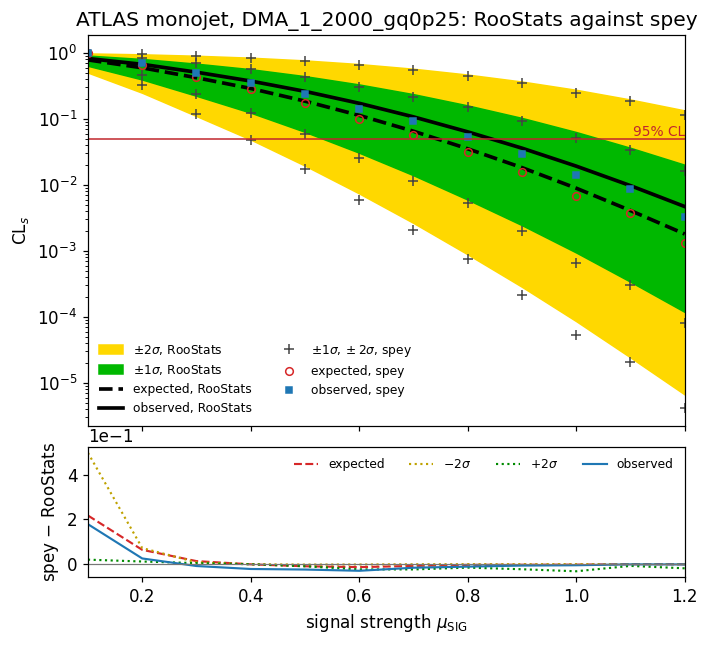

In [22]:
import matplotlib.pyplot as plt

brazil_plot(
    reference_cls,
    spey_cls,
    "ATLAS monojet, DMA_1_2000_gq0p25: RooStats against spey",
    poi_label=r"signal strength $\mu_{\rm SIG}$",
    log=True,
)
plt.show()

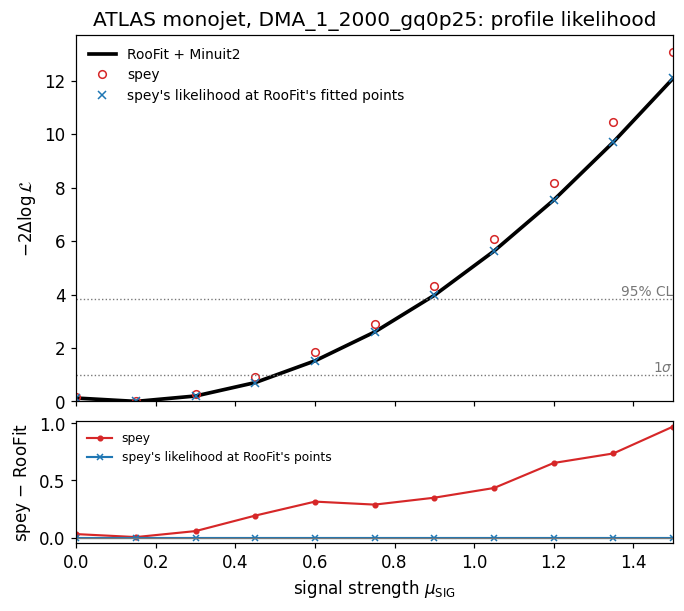

In [23]:
chi2_plot(
    reference_profile,
    spey_profile,
    "ATLAS monojet, DMA_1_2000_gq0p25: profile likelihood",
    poi_label=r"signal strength $\mu_{\rm SIG}$",
    spey_at_reference=spey_at_roofit,
)
plt.show()

**The two plots, read together.** The $\chi^2$ plot separates the likelihood from the
minimiser. Evaluated at the parameters `RooFit` fitted, `spey`'s log-likelihood reproduces
`RooFit`'s profile to $10^{-8}$ (blue crosses): both workflows evaluate the *same function*
of the same 150 parameters, which is the claim this section sets out to test. `spey`'s own
fits, however, do not reach the same minima. Its conditional fits stop above `RooFit`'s, by
up to one unit of $-2\Delta\log\mathcal{L}$ at $\mu=1.5$, so its curve rises too steeply.
The best fits, 0.1268 and 0.1310, differ by $10^{-3}$ in $-2\log\mathcal{L}$: the minimum is
flat there, and 0.1268 is also the value stored in the published workspace.

The Brazilian plot inherits this, mildly. Around the 95% line, where it matters, the observed
limit comes out at 0.81 against 0.85 from `RooStats`, the median expected at 0.73 against
0.75, and the $-2\sigma$ limits coincide. The large differences at $\mu\lesssim0.2$ are
where $\mathrm{CL}_s$ is close to one and the test statistic close to zero, so that a small
error in a fit is a large relative error in $\mathrm{CL}_s$.

**Why `spey`'s fits stop short.** `RooFit` provides no gradient, so `spey` differentiates the
likelihood numerically, with steps of about $10^{-8}$. The `RooFit` negative log-likelihood
of a workspace like this one is of order $10^{7}$ — a data-dependent constant, the bin
volumes of the extended term — so a single evaluation is only good to a few parts in
$10^{9}$, and each finite-difference derivative carries an error of order $0.1$. In some 150
dimensions that is enough to stop the optimiser short of the minimum. `RooMinimizer` avoids
the problem by offsetting the likelihood before it minimises, and the reference depends on
that as well: without the offset, every fit `RooStats` makes of the monojet workspace
fails.

So the likelihood is validated against the pure `RooFit` workflow to $10^{-8}$; what `spey`
infers from it on a model of this size is limited by the precision of its numerical
minimisation, at the level of 5% on the limits.

---
## 7. Injecting your own signal

The point of the interpreter is that a user with a new model only needs to know the
region names and their binning — `bin_map` tells them exactly that — and can then hand
`spey` a signal without ever touching `RooFit`.

Below, the published signal template is extracted from the signal-plus-background
workspace, injected into the *background-only* workspace, and the two are compared.

In [24]:
published = WorkspaceData(load_workspace(os.path.join(ATLAS, "sPlusBFit_postFit.root")))
nominal = published.nominal_parameters
template = np.array(
    published.expected_data(np.concatenate([[1.0], nominal[1:]]))
) - np.array(published.expected_data(np.concatenate([[0.0], nominal[1:]])))

signal_yields = {
    channel: [float(template[index])]
    for index, channel in enumerate(published.channel_names)
    if template[index] > 0.0
}
for channel, value in signal_yields.items():
    print(f"  {channel:16s} {value[0]:10.2f}")

  SR_200_cuts         1351.29
  SR_250_cuts         1041.62
  SR_300_cuts          766.13
  SR_350_cuts          548.74
  SR_400_cuts          681.70
  SR_500_cuts          370.21
  SR_600_cuts          211.50
  SR_700_cuts          125.61
  SR_800_cuts           78.53
  SR_900_cuts           47.70
  SR_1000_cuts          28.96
  SR_1100_cuts          18.62
  SR_1200_cuts          34.18


In [25]:
injected = spey.get_backend("root.roofit")(
    workspace=os.path.join(ATLAS, "bOnlyFit_postFit.root"),
    signal_yields=signal_yields,
    analysis="atlas-injected",
)
model = injected.backend.model
print("parameter of interest:", model.poi.GetName())
print("free parameters      :", model.npar)
print("is_alive             :", injected.is_alive)

zero = np.array(model.expected_data([0.0] + list(model.nominal_parameters[1:])))
one = np.array(model.expected_data([1.0] + list(model.nominal_parameters[1:])))
recovered = (one - zero)[: model.nbins]

print()
print(f"{'region':16s} {'requested':>12s} {'recovered':>12s}")
for index, channel in enumerate(model.channel_names):
    if channel in signal_yields:
        print(f"{channel:16s} {signal_yields[channel][0]:12.4f} {recovered[index]:12.4f}")

parameter of interest: mu
free parameters      : 147
is_alive             : True

region              requested    recovered
SR_200_cuts         1351.2946    1351.2946
SR_250_cuts         1041.6185    1041.6185
SR_300_cuts          766.1266     766.1266
SR_350_cuts          548.7405     548.7405
SR_400_cuts          681.7040     681.7040
SR_500_cuts          370.2099     370.2099
SR_600_cuts          211.5005     211.5005
SR_700_cuts          125.6093     125.6093
SR_800_cuts           78.5300      78.5300
SR_900_cuts           47.7045      47.7045
SR_1000_cuts          28.9629      28.9629
SR_1100_cuts          18.6165      18.6165
SR_1200_cuts          34.1795      34.1795


### Full inference on the injected model

Everything `spey` offers is now available. The two workspaces are not identical — the
published one also carries the signal theory systematics, which the injected signal does
not — so the results are close but not equal.

Each of the two limits below takes a few minutes: `RooFit` offers no analytic
gradient, so `spey` differentiates the 150-parameter likelihood numerically.


In [26]:
import time

start = time.time()
print("1 - CLs (injected) :", injected.exclusion_confidence_level()[0])
print(f"   ({time.time() - start:.0f} s)")
start = time.time()
print("1 - CLs (published):", splusb.exclusion_confidence_level()[0])
print(f"   ({time.time() - start:.0f} s)")

1 - CLs (injected) : 0.9809077457496393
   (221 s)


1 - CLs (published): 0.9843575551380127
   (106 s)
